<a href="https://colab.research.google.com/github/Sibgat-git/Medical-Insurance-Premium-Predictor/blob/main/Medical_Insurance_Premium_Predictor_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install git+https://github.com/Kaggle/learntools.git

  Cloning https://github.com/Kaggle/learntools.git to /tmp/pip-req-build-27mfoc8a
  Running command git clone --filter=blob:none --quiet https://github.com/Kaggle/learntools.git /tmp/pip-req-build-27mfoc8a
  Resolved https://github.com/Kaggle/learntools.git to commit a0c08ac1fa73dd42ba4aecf2cce045752f14f72b
  Preparing metadata (setup.py) ... done
  Created wheel for learntools: filename=learntools-0.3.5-py3-none-any.whl size=269685 sha256=9b074743fce3a7522c3eaa704285adb5a775d74e157ef2608238fc256deda3ce
  Stored in directory: /tmp/pip-ephem-wheel-cache-rtox0dq3/wheels/3e/56/95/47a8734b7e520ce6a601b2d09b8e0714eac8b3d59669123c80
Successfully built learntools


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error , r2_score
from sklearn.model_selection import train_test_split

df = pd.read_csv("insurance.csv")

df.head()




,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


age                 0
bmi                 0
children            0
charges             0
sex_male            0
smoker_yes          0
region_northwest    0
region_southeast    0
region_southwest    0
dtype: int64


Text(0.5, 1.0, 'Feature Correlation Matrix')

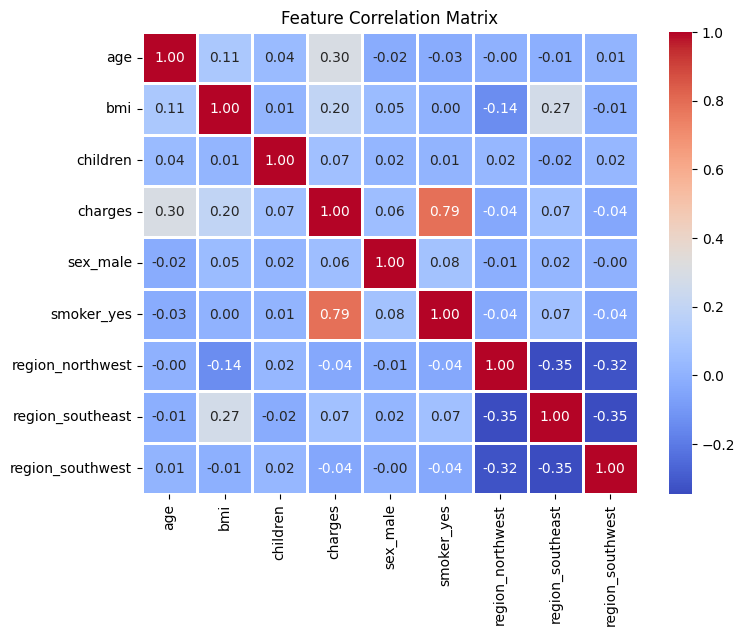

In [10]:
print(df.isnull().sum())

df_encoded = pd.get_dummies(df, drop_first = True)
plt.figure(figsize=(8,6))

sns.heatmap(
    df_encoded.corr(),annot=True, cmap="coolwarm" ,fmt = ".2f", linewidth = 1
)

plt.title("Feature Correlation Matrix")


In [16]:
X = df_encoded.drop(columns = ["charges"])
y = df_encoded["charges"]

x_train, x_test, y_train, y_test = train_test_split(X,y)

model = LinearRegression()

model.fit(x_train, y_train)

y_pred = model.predict(x_test)

r2 = r2_score(y_test,y_pred)


rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"Model R² Score: {r2:.4f}")
print(f"Root Mean Squared Error (RMSE): ${rmse:.2f}")

Model R² Score: 0.8233
Root Mean Squared Error (RMSE): $5297.59


In [18]:

coefficients = pd.DataFrame(
    model.coef_, X.columns, columns=["Coefficient (Impact on Cost)"]
)
coefficients.sort_values(
    by="Coefficient (Impact on Cost)", ascending=False
)

,Coefficient (Impact on Cost)
smoker_yes,23296.676385
children,522.474085
bmi,341.866807
age,259.019283
sex_male,-155.455063
region_northwest,-265.663638
region_southeast,-977.407733
region_southwest,-1194.537455


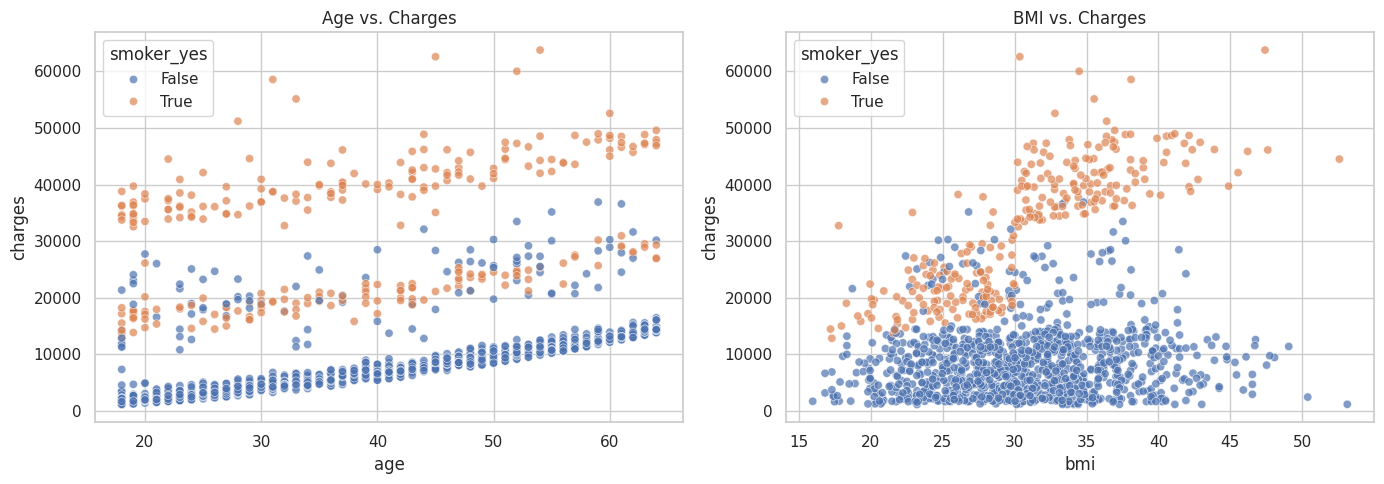

In [20]:


sns.set_theme(style="whitegrid")

# Create a figure with 2 subplots (Age vs Charges, BMI vs Charges)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Age vs Charges (colored by smoker status using the encoded 'smoker_yes' column)
sns.scatterplot(
    data=df, x="age", y="charges", hue="smoker_yes", alpha=0.7, ax=axes[0]
)
axes[0].set_title("Age vs. Charges")

# 2. BMI vs Charges
sns.scatterplot(
    data=df, x="bmi", y="charges", hue="smoker_yes", alpha=0.7, ax=axes[1]
)
axes[1].set_title("BMI vs. Charges")

plt.tight_layout()
plt.show()

In [21]:



custom_data = {
    "age": 23,
    "bmi": 26,
    "children": 0,
    "sex_male": 1,
    "smoker_yes": 0,
    "region_northwest": 1,
    "region_southeast": 0,
    "region_southwest": 0,
}


custom_df = pd.DataFrame([custom_data], columns=X.columns)


predicted_charge = model.predict(custom_df)

print(
    f"Predicted Medical Cost for this profile: ${predicted_charge[0]:.2f}"
)

Predicted Medical Cost for this profile: $2483.88


```markdown
#  Medical Insurance Premium Predictor

###  Project Overview
This project applies machine learning to predict individual annual medical insurance costs based on demographic and lifestyle features (Age, BMI, Smoking Status, Region, etc.). It demonstrates the complete end-to-end data science lifecycle, from Exploratory Data Analysis (EDA) and feature encoding to predictive modeling, evaluation, and business interpretation.

###  Key Professional Highlights
* **Feature Analysis:** Uncovered that smoking status is the single largest driver of medical charges, followed by age and BMI.
* **Model Selection:** Implemented and compared linear and non-linear regression algorithms to optimize prediction accuracy.
* **Business Impact:** Translates yearly premium predictions into practical monthly budgeting metrics.

---
```

In [ ]:

from sklearn.ensemble import RandomForestRegressor

# Initialize and train Random Forest
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(x_train, y_train)

# Predict
y_pred_rf = rf_model.predict(x_test)

# Evaluate RF
r2_rf = r2_score(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))

# Compare models in a clean DataFrame
performance_comparison = pd.DataFrame({
    "Metric": ["R² Score (Variance Explained)", "Root Mean Squared Error (RMSE)"],
    "Linear Regression Baseline": [f"{r2:.4f}", f"${rmse:.2f}"],
    "Random Forest Regressor": [f"{r2_rf:.4f}", f"${rmse_rf:.2f}"]
})

print("🏆 MODEL PERFORMANCE COMPARISON 🏆")
display(performance_comparison)

In [25]:
# --- 2. Interactive Calculator UI for LinkedIn Showcases ---
# @title 🎛️ Interactive Premium Calculator
# @markdown Fill out the demographic details below to calculate the predicted annual & monthly costs using the best-performing model (Random Forest).

# Input fields using Google Colab form parameter widgets
age = 23 # @param {type:"slider", min:18, max:100, step:1}
bmi = 26.2 # @param {type:"number"}
children = 0 # @param {type:"slider", min:0, max:5, step:1}
sex = "male" # @param ["female", "male"]
smoker = "no" # @param ["yes", "no"]
region = "northwest" # @param ["northeast", "northwest", "southeast", "southwest"]

# Encode the user input to match the training feature format
user_profile = {
    "age": age,
    "bmi": bmi,
    "children": children,
    "sex_male": 1 if sex == "male" else 0,
    "smoker_yes": 1 if smoker == "yes" else 0,
    "region_northwest": 1 if region == "northwest" else 0,
    "region_southeast": 1 if region == "southeast" else 0,
    "region_southwest": 1 if region == "southwest" else 0
}

# Create DataFrame
user_df = pd.DataFrame([user_profile], columns=X.columns)

# Run prediction using the higher-accuracy Random Forest Model (with fallback to baseline model)
try:
    annual_prediction = rf_model.predict(user_df)[0]
    model_used = "Random Forest Regressor"
except NameError:
    annual_prediction = model.predict(user_df)[0]
    model_used = "Linear Regression (Baseline)"

monthly_prediction = annual_prediction / 12

print("-" * 50)
print(" PREDICTED INSURANCE PREMIUMS")
print("-" * 50)
print(f" Profile: {age}yo {sex.title()} | BMI: {bmi} | Smoker: {smoker.title()} | Region: {region.upper()}")
print(f" Model Used: {model_used}")
print(f" Estimated Annual Cost: ${annual_prediction:,.2f}")
print(f" Estimated Monthly Cost: ${monthly_prediction:,.2f}")
print("-" * 50)

--------------------------------------------------
 PREDICTED INSURANCE PREMIUMS
--------------------------------------------------
 Profile: 23yo Male | BMI: 26.2 | Smoker: No | Region: NORTHWEST
 Model Used: Linear Regression (Baseline)
 Estimated Annual Cost: $2,552.25
 Estimated Monthly Cost: $212.69
--------------------------------------------------
